# **허깅페이스 모델 로드**

In [28]:
from transformers import pipeline
from PIL import Image

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [2]:
model = pipeline("image-classification", model="dima806/dogs_cats_image_detection")


config.json:   0%|          | 0.00/719 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/325 [00:00<?, ?B/s]

# **예측**

In [11]:
TEST_PATH   = "../datas/catdog"
test_datagen  = ImageDataGenerator( rescale = 1.0 / 255.0)
test_gen = test_datagen.flow_from_directory(TEST_PATH, batch_size=20, class_mode=None, shuffle=False, target_size=(240, 160))

Found 50 images belonging to 1 classes.


In [42]:
test_gen.filenames[:5]

['test/1.jpg', 'test/10.jpg', 'test/11.jpg', 'test/12.jpg', 'test/13.jpg']

In [43]:
os.path.join(TEST_PATH, 'test/1.jpg').replace("\\", "/")

'../datas/catdog/test/1.jpg'

In [32]:
pred_proba = []
valid_filenames = []

for filename in test_gen.filenames:
    if ".ipynb_checkpoints" in filename:
        continue
        
    #full_img_path = TEST_PATH + "\\" + filename
    full_img_path = os.path.join(TEST_PATH, filename).replace("\\", "/")

    try:
        predictions = model(full_img_path) #---model.predict() XXXXX
    except Exception as e:
        print(f"파일을 읽는 도중 오류가 발생해 건너뜁니다: {full_img_path} | 에러: {e}")
        continue

    dog_score = 0.0
    for pred in predictions:
        current_label = pred['label'].lower() # "Dogs" -> "dogs", "Cats" -> "cats"으로 일치시킴
        
        if current_label == 'dogs':
            dog_score = pred['score']
            break
        elif current_label == 'cats':
            # 만약 개 리스트를 못 찾고 고양이 스코어만 확인된다면 1에서 빼서 개 확률로 역산
            dog_score = 1.0 - pred['score']
            break
                
    pred_proba.append(dog_score)
    valid_filenames.append(filename)

pred_proba = np.array(pred_proba)    

In [33]:
print(pred_proba)

[0.99637669 0.0047192  0.00482106 0.99571025 0.00433111 0.00441337
 0.00473785 0.00447512 0.99523073 0.9965964  0.0046894  0.9965328
 0.0045765  0.99642986 0.00442815 0.99659193 0.9963643  0.0049873
 0.99662638 0.99635798 0.00455523 0.67524153 0.99632818 0.99653375
 0.99640024 0.72815365 0.99600911 0.00490522 0.00485659 0.00439376
 0.00452191 0.00603527 0.99176639 0.99585778 0.00487173 0.99618596
 0.99660516 0.99637336 0.99600035 0.00478375 0.9949255  0.00421458
 0.99617898 0.99612302 0.00492024 0.00483131 0.00550997 0.00471151
 0.0045042  0.00395799]


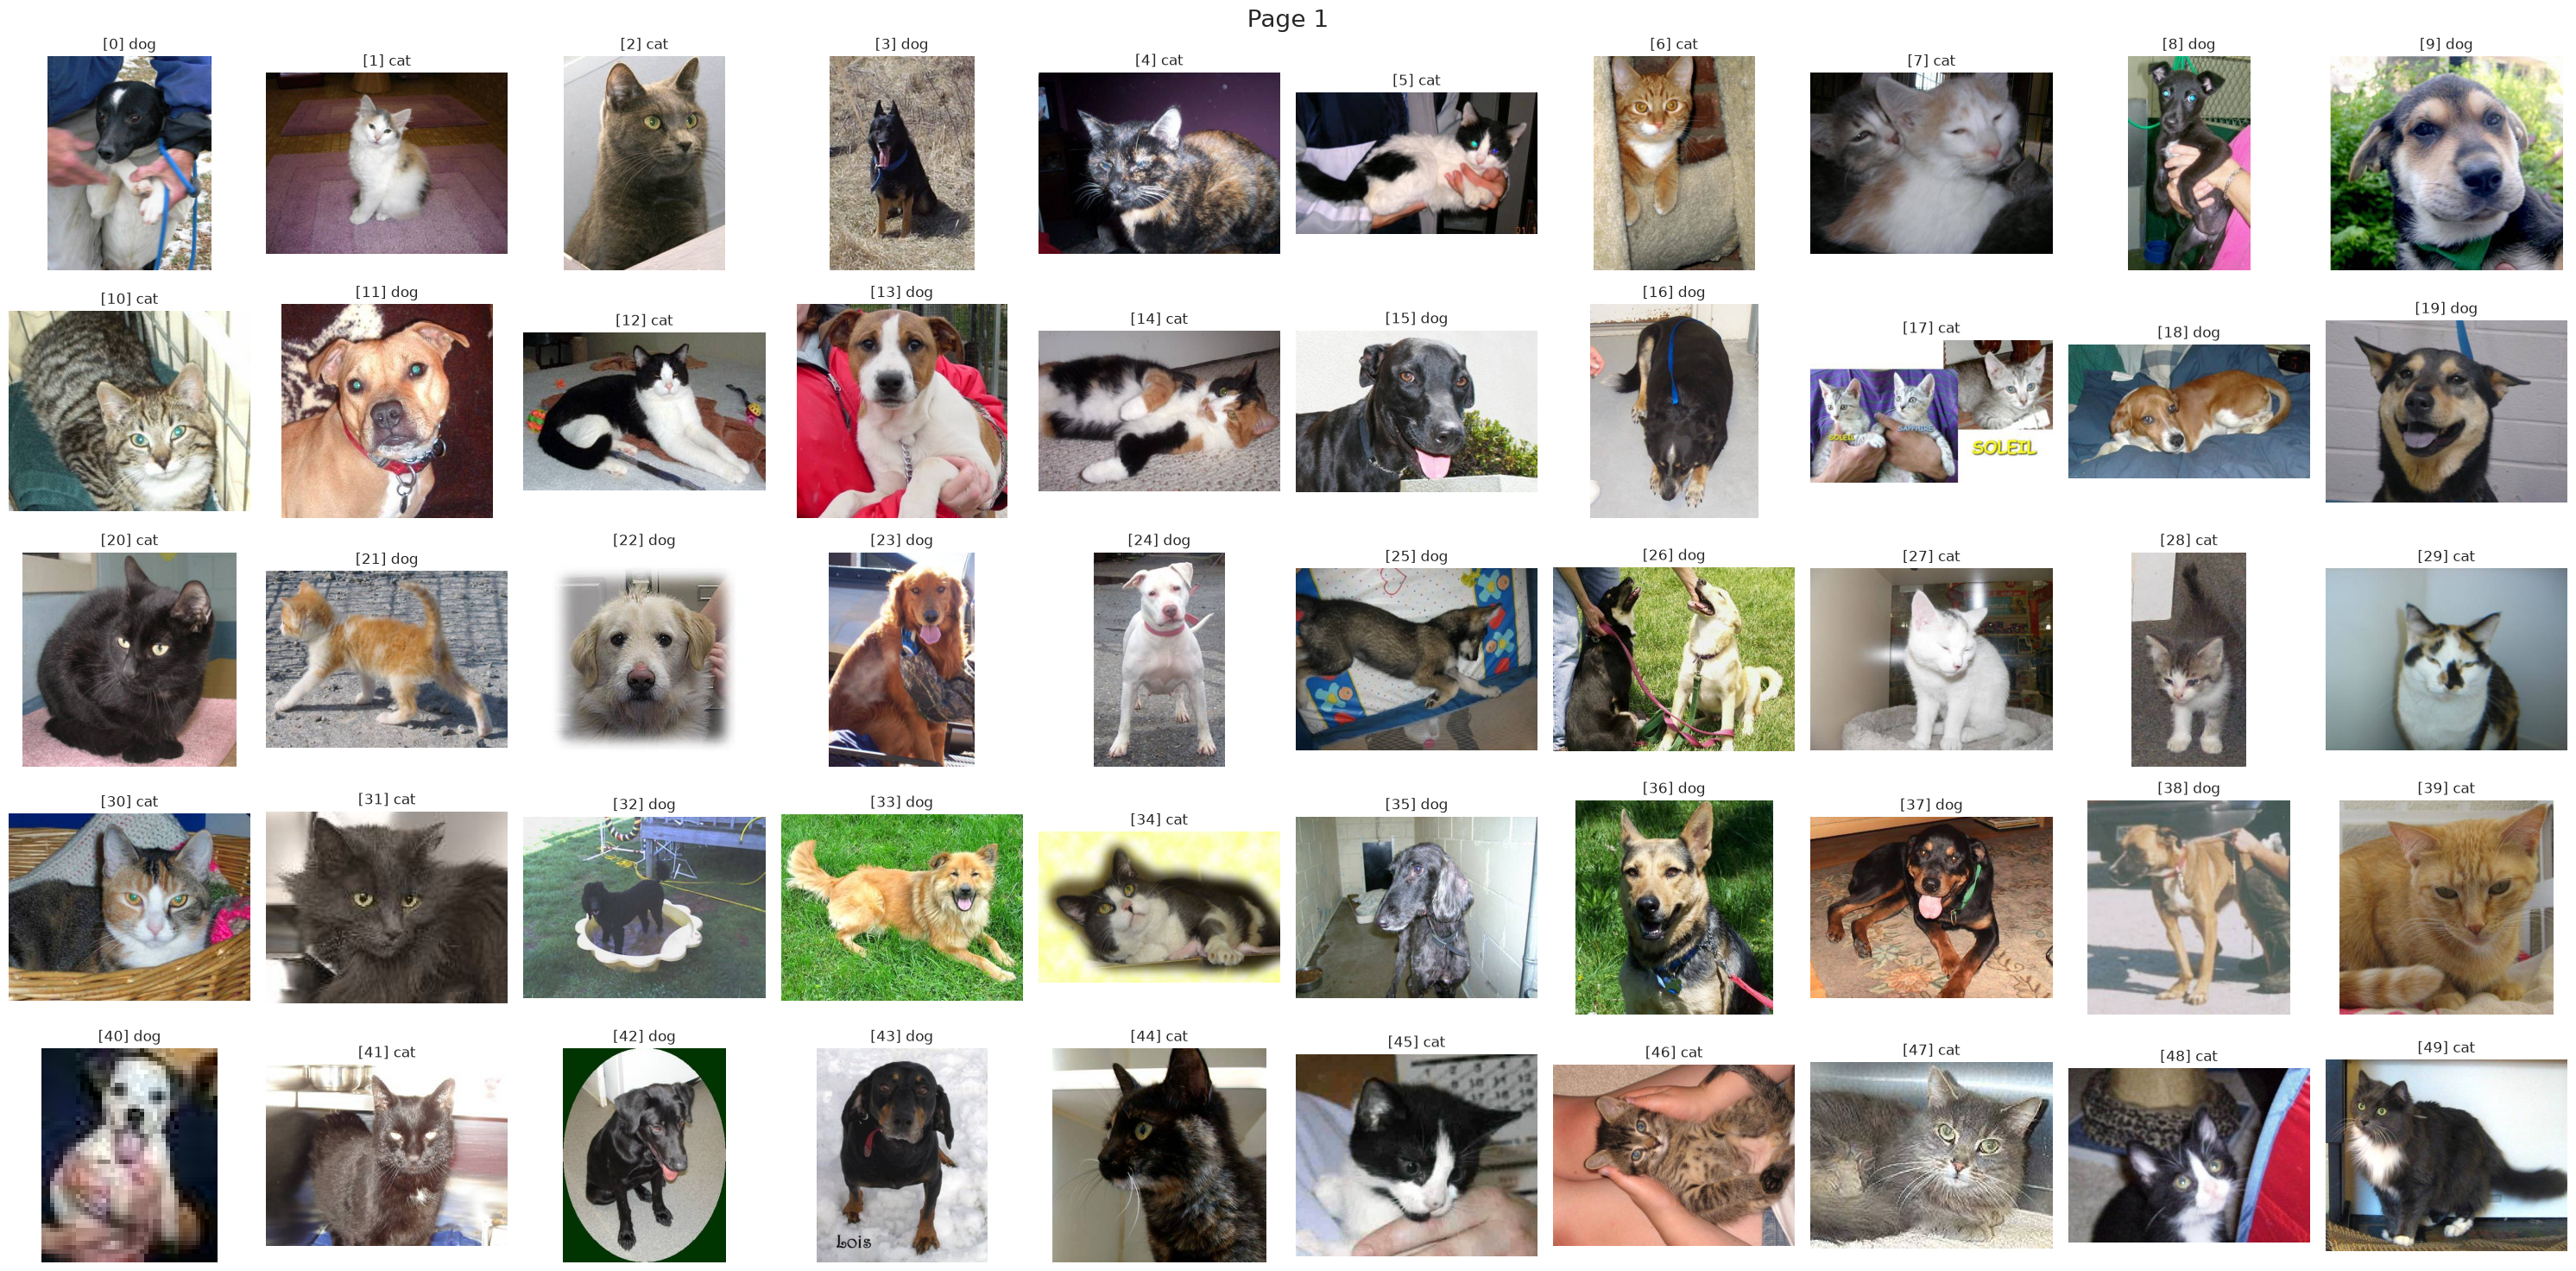

In [40]:
# 5행 10열 = 한 페이지당 최대 50개 이미지
rows, cols = 5, 10
images_per_page = rows * cols
total_images = len(pred_proba)

# 전체 데이터를 50개씩 나누어 반복 실행
for page_idx in range((total_images + images_per_page - 1) // images_per_page):
    
    # 새로운 페이지(5행 10열) 서브플롯 생성 (가로를 넓게 설정)
    fig, axes = plt.subplots(rows, cols, figsize=(30, 15))
    axes = axes.flatten()  # 2차원 배열을 1차원으로 펼치기
    
    # 현재 페이지에 들어갈 시작 인덱스와 끝 인덱스 계산
    start_idx = page_idx * images_per_page
    end_idx = min(start_idx + images_per_page, total_images)
    
    # 50개 칸 중에서 실제 데이터가 채워질 부분만 루프
    for i in range(start_idx, end_idx):
        # 50칸 중 몇 번째 칸에 그릴지 계산 (0 ~ 49)
        ax_idx = i - start_idx  
        
        # 1. 예측 결과 콘솔 출력
        if pred_proba[i] > 0.5:
            #print(f"dog {valid_filenames[i]}")
            label = "dog"
        else:
            #print(f"cat {valid_filenames[i]}")
            label = "cat"
        
        # 2. 이미지 로드 및 해당 칸에 시각화
        img_display_path = os.path.join(TEST_PATH, valid_filenames[i]).replace("\\", "/")
        
        try:
            img = mpimg.imread(img_display_path)
            axes[ax_idx].imshow(img)
            axes[ax_idx].set_title(f"[{i}] {label}", fontsize=12)
        except Exception as e:
            # 이미지 로드 실패 시 에러 메시지 표시
            axes[ax_idx].text(0.5, 0.5, "Load Error", ha='center', va='center', color='red')
            axes[ax_idx].set_title(f"[{i}] Error", fontsize=12)
            
        axes[ax_idx].axis('off')

    # 마지막 페이지에서 50개가 안 채워지고 남은 빈 칸들은 숨김 처리
    for j in range(end_idx - start_idx, images_per_page):
        axes[j].axis('off')
        
    plt.suptitle(f"Page {page_idx + 1}", fontsize=20, y=0.98)
    plt.tight_layout()
    plt.show()

dog test/1.jpg


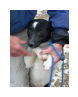

cat test/10.jpg


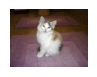

cat test/11.jpg


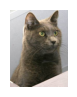

dog test/12.jpg


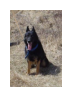

cat test/13.jpg


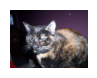

cat test/14.jpg


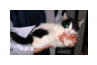

cat test/15.jpg


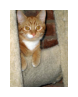

cat test/16.jpg


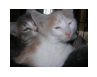

dog test/17.jpg


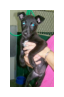

dog test/18.jpg


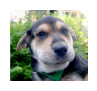

cat test/19.jpg


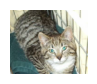

dog test/2.jpg


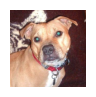

cat test/20.jpg


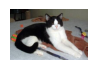

dog test/21.jpg


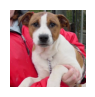

cat test/22.jpg


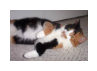

dog test/23.jpg


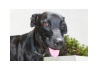

dog test/24.jpg


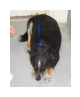

cat test/25.jpg


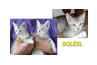

dog test/26.jpg


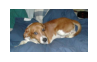

dog test/27.jpg


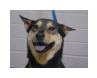

cat test/28.jpg


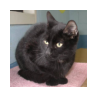

dog test/29.jpg


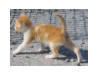

dog test/3.jpg


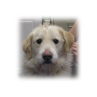

dog test/30.jpg


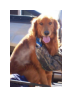

dog test/31.jpg


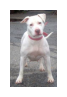

dog test/32.jpg


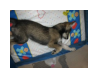

dog test/33.jpg


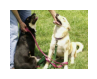

cat test/34.jpg


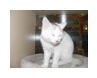

cat test/35.jpg


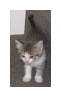

cat test/36.jpg


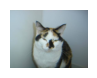

cat test/37.jpg


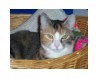

cat test/38.jpg


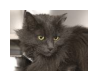

dog test/39.jpg


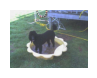

dog test/4.jpg


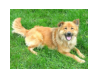

cat test/40.jpg


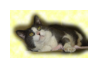

dog test/41.jpg


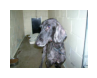

dog test/42.jpg


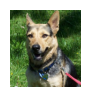

dog test/43.jpg


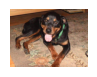

dog test/44.jpg


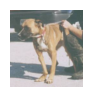

cat test/45.jpg


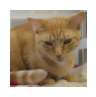

dog test/46.jpg


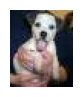

cat test/47.jpg


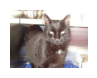

dog test/48.jpg


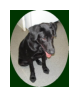

dog test/49.jpg


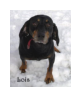

cat test/5.jpg


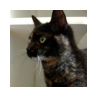

cat test/50.jpg


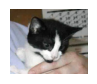

cat test/6.jpg


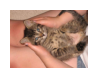

cat test/7.jpg


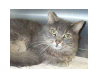

cat test/8.jpg


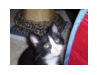

cat test/9.jpg


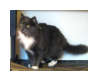

In [34]:

for i in range(len(pred_proba)):
    if pred_proba[i] > 0.5:
        print(f"dog {valid_filenames[i]}")
    else: 
        print(f"cat {valid_filenames[i]}")

    plt.figure(figsize=(1, 1))
    
    # 시각화할 때도 올바른 경로 포맷 유지
    img_display_path = os.path.join(TEST_PATH, valid_filenames[i]).replace("\\", "/")
    img = mpimg.imread(img_display_path)
    
    plt.imshow(img)     
    plt.axis('off')
    plt.grid(False)
    plt.show()   